# 🏨 Báo cáo Thống kê Mô tả: Tập Dữ liệu Hotel Booking Demand (HOTEL)

Tập dữ liệu chứa thông tin đặt phòng thực tế của hai loại khách sạn: **City Hotel** (khách sạn đô thị) và **Resort Hotel** (khách sạn nghỉ dưỡng).
Mục tiêu của báo cáo là thực hiện thống kê mô tả toàn diện về chất lượng dữ liệu, phân phối các biến định lượng, biến định tính và phân tích xu hướng biến mục tiêu hủy phòng (`is_canceled`).

---


In [1]:
import os
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Thiết lập phong cách hiển thị đồ thị
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11
pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', lambda x: '%.3f' % x)

print("Đã tải các thư viện phân tích thành công!")


Đã tải các thư viện phân tích thành công!


## 1. Nạp và Kiểm tra Tổng quan Tập Dữ liệu

Tập dữ liệu được lưu trữ tại file `data/raw/HOTEL/hotel_bookings.csv`.
Chúng ta sẽ kiểm tra số lượng quan sát (dòng), số lượng thuộc tính (cột) và kiểu dữ liệu của từng trường.


In [2]:
# Xác định đường dẫn file dữ liệu
project_root = Path.cwd()
while not (project_root / 'data').exists() and project_root != project_root.parent:
    project_root = project_root.parent

data_path = project_root / 'data' / 'raw' / 'HOTEL' / 'hotel_bookings.csv'
print(f"Đường dẫn dữ liệu: {data_path.resolve()}")

df_hotel = pd.read_csv(data_path)
print(f"Kích thước tập dữ liệu: {df_hotel.shape[0]:,} dòng và {df_hotel.shape[1]} cột")
print(f"Dung lượng bộ nhớ ước tính: {df_hotel.memory_usage(deep=True).sum() / (1024**2):.2f} MB")
df_hotel.head(3)


Đường dẫn dữ liệu: C:\Users\admin\Documents\Thực tập VSF\Propensity\data\raw\HOTEL\hotel_bookings.csv


Kích thước tập dữ liệu: 119,390 dòng và 32 cột


Dung lượng bộ nhớ ước tính: 93.90 MB


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.000,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.000,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.000,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.000,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.000,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.000,0,0,Check-Out,2015-07-02


In [3]:
# Phân loại kiểu dữ liệu của các cột
dtype_counts = df_hotel.dtypes.value_counts()
print("Phân phối kiểu dữ liệu:")
print(dtype_counts)

print("\nDanh sách các cột phân loại (Object/Categorical):")
print(df_hotel.select_dtypes(include=['object']).columns.tolist())


Phân phối kiểu dữ liệu:
int64      16
object     12
float64     4
Name: count, dtype: int64

Danh sách các cột phân loại (Object/Categorical):
['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type', 'reservation_status', 'reservation_status_date']


## 2. Kiểm tra Chất lượng Dữ liệu & Giá trị Khuyết thiếu (Missing Values)

Xem xét các cột bị thiếu dữ liệu, số lượng dòng trùng lặp để lên phương án làm sạch.


In [4]:
# Tính toán số lượng và tỷ lệ missing values
missing = df_hotel.isnull().sum()
missing_pct = (missing / len(df_hotel)) * 100
missing_df = pd.DataFrame({'Missing_Count': missing, 'Missing_Percentage (%)': missing_pct})
missing_df = missing_df[missing_df['Missing_Count'] > 0].sort_values(by='Missing_Count', ascending=False)

print("Các cột chứa giá trị khuyết thiếu:")
display(missing_df)

duplicate_count = df_hotel.duplicated().sum()
print(f"Số lượng dòng trùng lặp hoàn toàn: {duplicate_count:,} ({duplicate_count/len(df_hotel)*100:.2f}%)")


Các cột chứa giá trị khuyết thiếu:


,Missing_Count,Missing_Percentage (%)
company,112593,94.307
agent,16340,13.686
country,488,0.409
children,4,0.003


Số lượng dòng trùng lặp hoàn toàn: 31,994 (26.80%)


## 3. Thống kê Biến Mục tiêu: Tỷ lệ Hủy phòng (`is_canceled`)

Trong bài toán dự đoán xu hướng (Propensity Modeling), `is_canceled` là nhãn mục tiêu nhị phân:
- `0`: Khách hàng không hủy (Check-in thành công).
- `1`: Khách hàng hủy đặt phòng.


,Số lượng,Tỷ lệ (%)
Không hủy (0),75166,62.958
Hủy phòng (1),44224,37.042


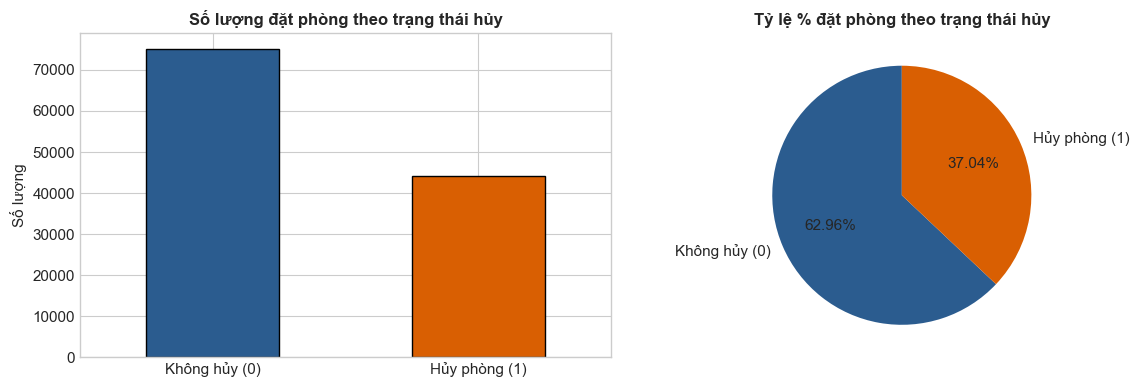

In [5]:
target_counts = df_hotel['is_canceled'].value_counts()
target_pct = df_hotel['is_canceled'].value_counts(normalize=True) * 100

summary_target = pd.DataFrame({'Số lượng': target_counts, 'Tỷ lệ (%)': target_pct})
summary_target.index = ['Không hủy (0)', 'Hủy phòng (1)']
display(summary_target)

# Trực quan hóa biến mục tiêu
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
colors = ['#2b5c8f', '#d95f02']

summary_target['Số lượng'].plot(kind='bar', ax=ax[0], color=colors, edgecolor='black')
ax[0].set_title("Số lượng đặt phòng theo trạng thái hủy", fontsize=12, fontweight='bold')
ax[0].set_ylabel("Số lượng")
ax[0].tick_params(axis='x', rotation=0)

summary_target['Tỷ lệ (%)'].plot(kind='pie', ax=ax[1], autopct='%1.2f%%', colors=colors, startangle=90)
ax[1].set_title("Tỷ lệ % đặt phòng theo trạng thái hủy", fontsize=12, fontweight='bold')
ax[1].set_ylabel("")

plt.tight_layout()
plt.show()


## 4. Thống kê Mô tả Biến Định lượng (Numerical Features)

Các chỉ số thống kê cơ bản: Trung bình (Mean), Độ lệch chuẩn (Std), Giá trị nhỏ nhất (Min), Tứ phân vị (25%, 50% Median, 75%) và Giá trị lớn nhất (Max).


In [6]:
num_cols = [
    'lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights',
    'adults', 'children', 'babies', 'previous_cancellations',
    'previous_bookings_not_canceled', 'booking_changes',
    'days_in_waiting_list', 'adr', 'required_car_parking_spaces',
    'total_of_special_requests'
]

desc_stats = df_hotel[num_cols].describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']]
desc_stats['IQR'] = desc_stats['75%'] - desc_stats['25%']
desc_stats['Skewness'] = df_hotel[num_cols].skew()
display(desc_stats)


,count,mean,std,min,25%,50%,75%,max,IQR,Skewness
lead_time,119390.000,104.011,106.863,0.000,18.000,69.000,160.000,737.000,142.000,1.347
stays_in_weekend_nights,119390.000,0.928,0.999,0.000,0.000,1.000,2.000,19.000,2.000,1.380
stays_in_week_nights,119390.000,2.500,1.908,0.000,1.000,2.000,3.000,50.000,2.000,2.862
adults,119390.000,1.856,0.579,0.000,2.000,2.000,2.000,55.000,0.000,18.318
children,119386.000,0.104,0.399,0.000,0.000,0.000,0.000,10.000,0.000,4.113
babies,119390.000,0.008,0.097,0.000,0.000,0.000,0.000,10.000,0.000,24.647
previous_cancellations,119390.000,0.087,0.844,0.000,0.000,0.000,0.000,26.000,0.000,24.458
previous_bookings_not_canceled,119390.000,0.137,1.497,0.000,0.000,0.000,0.000,72.000,0.000,23.540
booking_changes,119390.000,0.221,0.652,0.000,0.000,0.000,0.000,21.000,0.000,6.000
days_in_waiting_list,119390.000,2.321,17.595,0.000,0.000,0.000,0.000,391.000,0.000,11.944


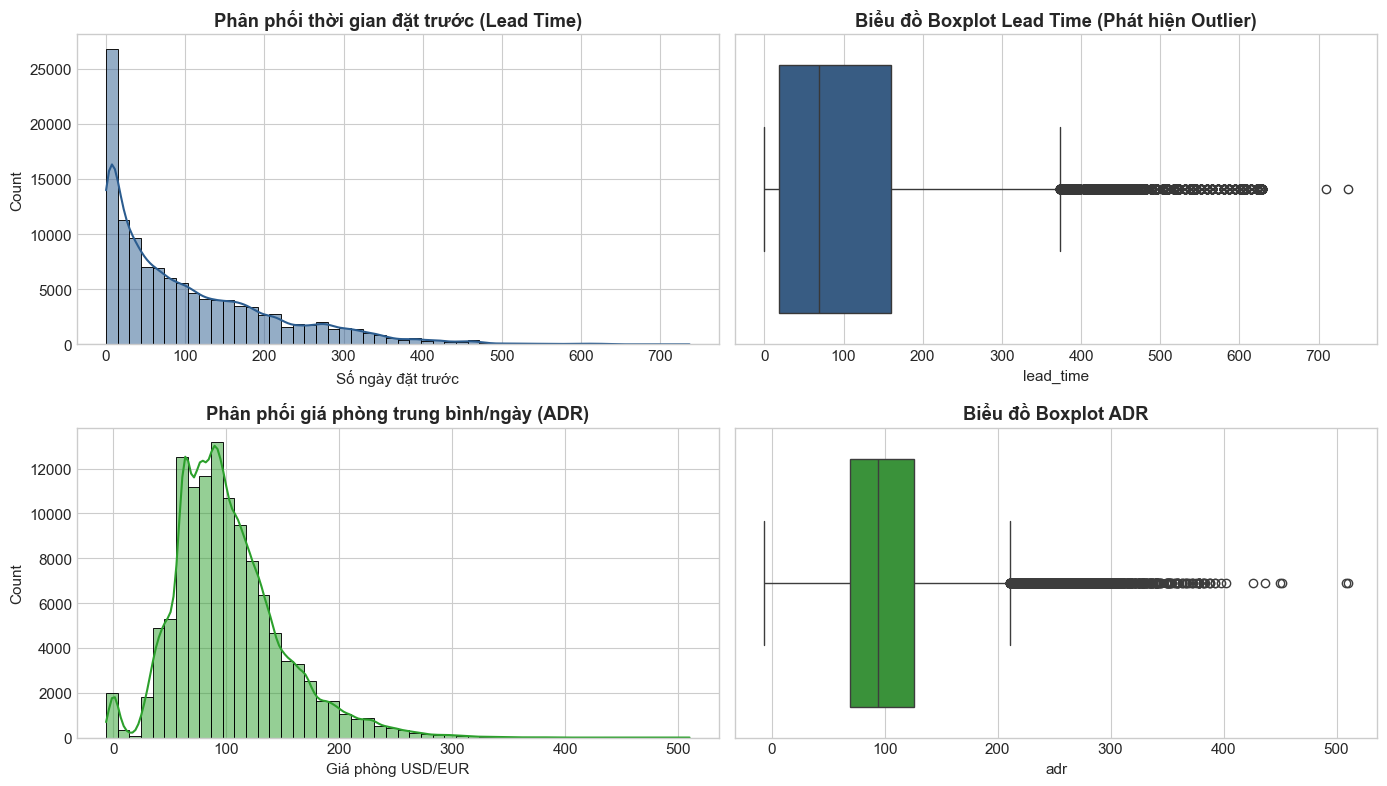

In [7]:
# Trực quan hóa phân phối của 2 biến quan trọng: lead_time và adr (Average Daily Rate)
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# Lead Time
sns.histplot(df_hotel['lead_time'], bins=50, kde=True, ax=axes[0, 0], color='#2b5c8f')
axes[0, 0].set_title("Phân phối thời gian đặt trước (Lead Time)", fontweight='bold')
axes[0, 0].set_xlabel("Số ngày đặt trước")

sns.boxplot(x=df_hotel['lead_time'], ax=axes[0, 1], color='#2b5c8f')
axes[0, 1].set_title("Biểu đồ Boxplot Lead Time (Phát hiện Outlier)", fontweight='bold')

# ADR (loại bỏ outlier cực đoan > 1000 để vẽ chart rõ ràng)
adr_filtered = df_hotel[df_hotel['adr'] < 1000]['adr']
sns.histplot(adr_filtered, bins=50, kde=True, ax=axes[1, 0], color='#2ca02c')
axes[1, 0].set_title("Phân phối giá phòng trung bình/ngày (ADR)", fontweight='bold')
axes[1, 0].set_xlabel("Giá phòng USD/EUR")

sns.boxplot(x=adr_filtered, ax=axes[1, 1], color='#2ca02c')
axes[1, 1].set_title("Biểu đồ Boxplot ADR", fontweight='bold')

plt.tight_layout()
plt.show()


## 5. Thống kê Mô tả Biến Định tính (Categorical Features)

Khám phá tần suất xuất hiện và tỷ lệ phân bố của các phân khúc khách hàng, loại khách sạn và kênh tiếp thị.


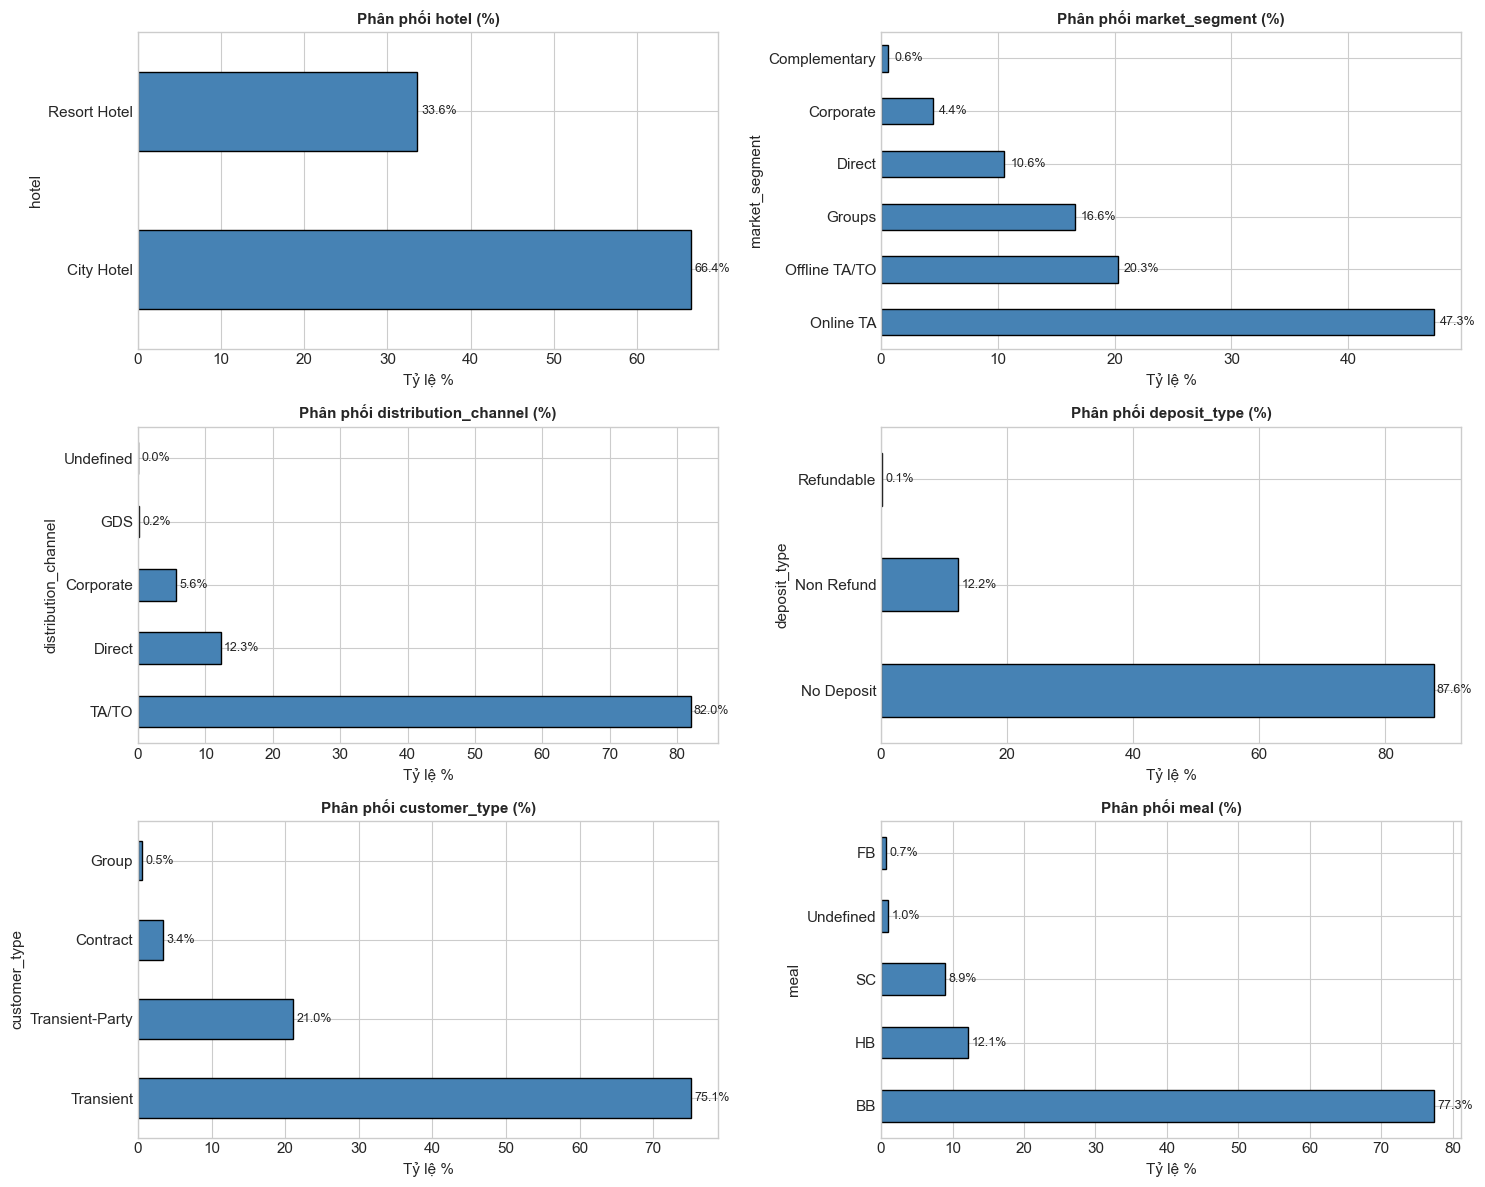

In [8]:
cat_features = ['hotel', 'market_segment', 'distribution_channel', 'deposit_type', 'customer_type', 'meal']

fig, axes = plt.subplots(3, 2, figsize=(15, 12))
axes = axes.flatten()

for i, col in enumerate(cat_features):
    counts = df_hotel[col].value_counts(normalize=True) * 100
    counts.head(6).plot(kind='barh', ax=axes[i], color='#4682b4', edgecolor='black')
    axes[i].set_title(f"Phân phối {col} (%)", fontweight='bold', fontsize=11)
    axes[i].set_xlabel("Tỷ lệ %")
    for idx, val in enumerate(counts.head(6)):
        axes[i].text(val + 0.5, idx, f"{val:.1f}%", va='center', fontsize=9)

plt.tight_layout()
plt.show()


In [9]:
# Top 10 quốc gia có lượng khách đặt nhiều nhất
top_countries = df_hotel['country'].value_counts().head(10)
top_countries_pct = (top_countries / len(df_hotel)) * 100

df_top_c = pd.DataFrame({'Lượt đặt': top_countries, 'Tỷ lệ (%)': top_countries_pct})
print("Top 10 quốc tịch khách hàng:")
display(df_top_c)


Top 10 quốc tịch khách hàng:


,Lượt đặt,Tỷ lệ (%)
country,,
PRT,48590,40.699
GBR,12129,10.159
FRA,10415,8.724
ESP,8568,7.176
DEU,7287,6.104
ITA,3766,3.154
IRL,3375,2.827
BEL,2342,1.962
BRA,2224,1.863


## 6. Thống kê Xu hướng Thời gian & Mùa vụ (Temporal Distribution)


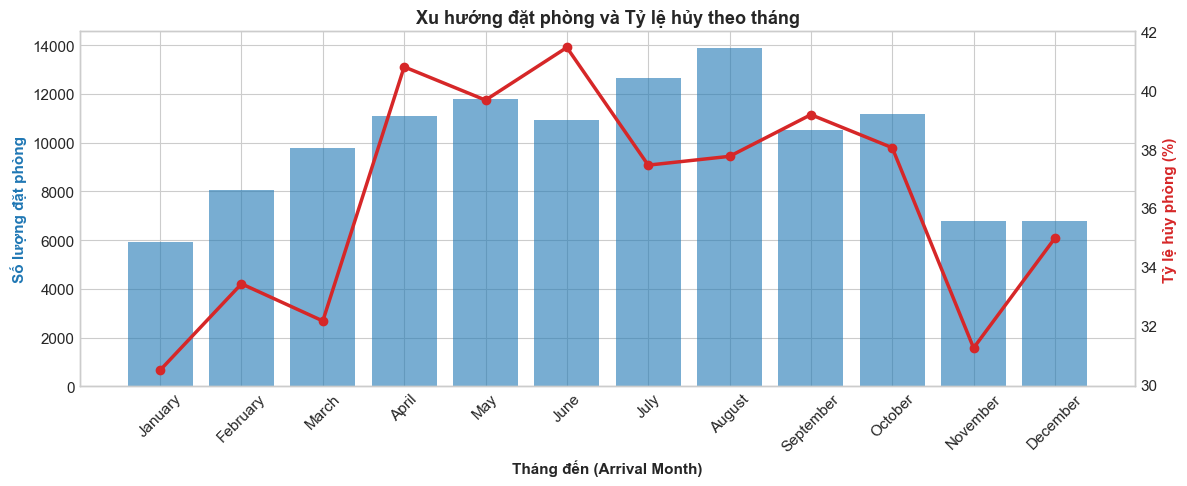

In [10]:
month_order = [
    'January', 'February', 'March', 'April', 'May', 'June',
    'July', 'August', 'September', 'October', 'November', 'December'
]

monthly_bookings = df_hotel['arrival_date_month'].value_counts().reindex(month_order)
monthly_cancel_rate = df_hotel.groupby('arrival_date_month')['is_canceled'].mean().reindex(month_order) * 100

fig, ax1 = plt.subplots(figsize=(12, 5))

color = 'tab:blue'
ax1.set_xlabel('Tháng đến (Arrival Month)', fontweight='bold')
ax1.set_ylabel('Số lượng đặt phòng', color=color, fontweight='bold')
ax1.bar(monthly_bookings.index, monthly_bookings.values, color=color, alpha=0.6, label='Tổng lượt đặt')
ax1.tick_params(axis='x', rotation=45)

ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Tỷ lệ hủy phòng (%)', color=color, fontweight='bold')
ax2.plot(monthly_cancel_rate.index, monthly_cancel_rate.values, color=color, marker='o', linewidth=2.5, label='Tỷ lệ hủy %')
ax2.grid(False)

plt.title("Xu hướng đặt phòng và Tỷ lệ hủy theo tháng", fontsize=13, fontweight='bold')
fig.tight_layout()
plt.show()


## 7. Tóm tắt Kết quả Phân tích & Đề xuất (Summary)

### Data Analysis Key Findings
- **Quy mô dữ liệu**: Tập dữ liệu gồm **119,390 dòng** và **32 cột**, đại diện cho 2 phân khúc khách sạn: City Hotel (66.4%) và Resort Hotel (33.6%).
- **Tỷ lệ hủy phòng (Target)**: Biến mục tiêu `is_canceled` có tỷ lệ hủy là **37.04%** (44,224 đơn hủy), cho thấy tỷ lệ churn/hủy đơn rất lớn, cần xây dựng mô hình dự đoán xu hướng hủy (Cancellation Propensity).
- **Giá trị khuyết thiếu**: 
  - `company`: thiếu 94.3% (chỉ một số ít đặt qua công ty doanh nghiệp).
  - `agent`: thiếu 13.69% (khách đặt trực tiếp không qua đại lý).
  - `country`: thiếu 488 dòng (0.41%).
  - `children`: thiếu 4 dòng.
- **Thời gian đặt trước (Lead Time)**: Rất biến động với trung bình **104 ngày**, trung vị là **69 ngày**, cá biệt lên tới 737 ngày. Các đơn đặt trước càng xa thì xác suất hủy càng cao.
- **Giá phòng trung bình (ADR)**: Trung vị là **94.58 EUR**, trung bình 101.83 EUR. Có outlier âm (-6.38) và outlier cực lớn (5400) cần được xử lý clipping trong pipeline.
- **Kênh tiếp thị**: Kênh Online TA chiếm đa số áp đảo (**47.3%**), theo sau là Offline TA/TO (**20.3%**) và Groups (**16.6%**). Khách hàng từ Bồ Đào Nha (PRT) chiếm tỷ trọng cao nhất (**40.9%**).

### Insights or Next Steps
- **Chiến lược Feature Engineering**: Tạo thêm biến tỷ lệ thời gian lưu trú cuối tuần so với ngày thường (`weekend_ratio`), biến kết hợp số khách (`total_guests = adults + children + babies`), và gắn nhãn cờ khách quen (`is_repeated_guest`).
- **Mô hình hóa Propensity**: Sử dụng mô hình phân loại nhị phân (LightGBM/XGBoost) với mục tiêu dự đoán `is_canceled`, tập trung vào các đặc trưng có tính phân tách mạnh như `lead_time`, `deposit_type`, `previous_cancellations` và `total_of_special_requests`.
